# 信用卡欺诈检测：集成分类模型对比与不平衡样本处理

**香港城市大学 MSc Electronic Commerce · IS6400 课程项目（个人完成） · Notebook 5/5**

在信用卡交易数据集（creditcard-reduced，32,764 条记录，其中欺诈交易 492 条，正负样本约 1.5% : 98.5%）上完成不平衡分类任务：对比决策树、随机森林、Bagging、AdaBoost、Stacking 五种分类模型，使用准确率、精确率、召回率、F1 值与混淆矩阵评估；并通过 `class_weight="balanced"` 检验类别加权对欺诈识别效果（尤其是召回率）的影响。

**Question 1：**

In [1]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import StackingClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings(
    "ignore",
    category=FutureWarning,
    message=".*probability.*deprecated.*"
)

data = pd.read_csv('../data/creditcard-reduced.csv',header='infer')

Y = data['Class']
X = data.drop(['Class'],axis=1)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.4, random_state=1, stratify=Y)


Model: Decision Tree
Accuracy: 0.9998473981382573
Precision: 1.0
Recall: 0.9898477157360406
F-score: 0.9948979591836735


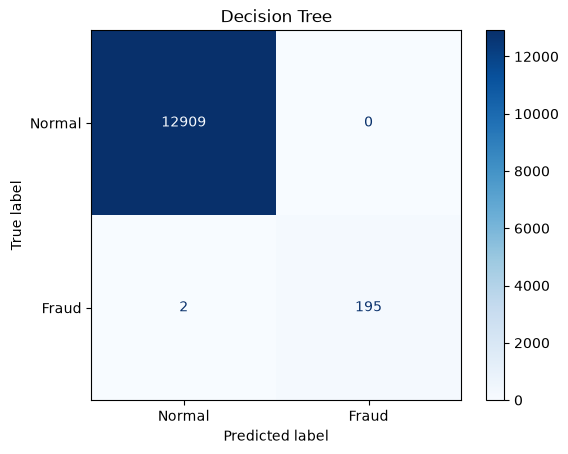


Model: Random Forest
Accuracy: 0.9972531664886312
Precision: 1.0
Recall: 0.817258883248731
F-score: 0.8994413407821229


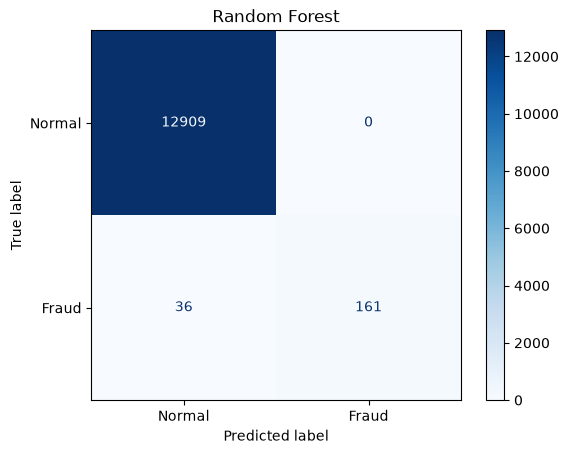


Model: Bagging
Accuracy: 0.9998473981382573
Precision: 1.0
Recall: 0.9898477157360406
F-score: 0.9948979591836735


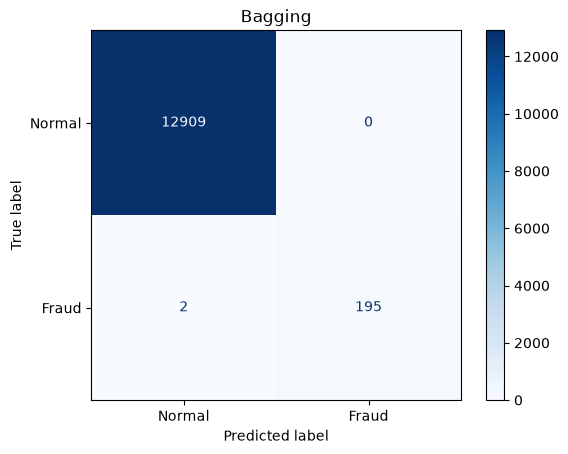


Model: AdaBoost
Accuracy: 0.9997710972073859
Precision: 0.9948979591836735
Recall: 0.9898477157360406
F-score: 0.9923664122137404


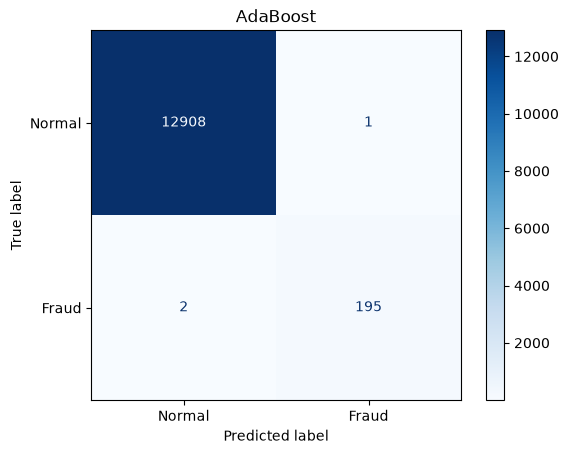


Model: StackingClassifier
Accuracy: 0.9994658934839005
Precision: 1.0
Recall: 0.9644670050761421
F-score: 0.9819121447028424


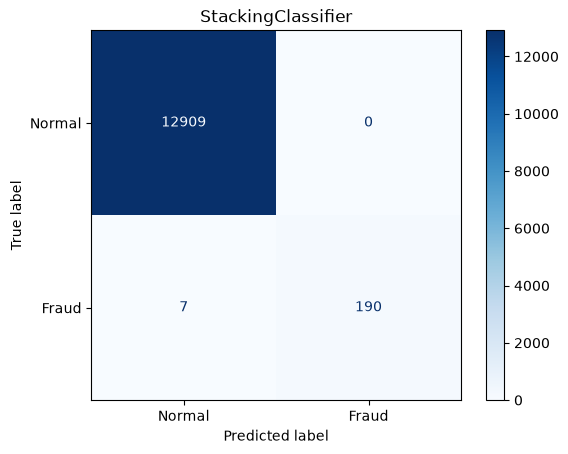

,Model,Accuracy,Precision,Recall,F-score
0,Decision Tree,0.999847,1.000000,0.989848,0.994898
1,Random Forest,0.997253,1.000000,0.817259,0.899441
2,Bagging,0.999847,1.000000,0.989848,0.994898
3,AdaBoost,0.999771,0.994898,0.989848,0.992366
4,StackingClassifier,0.999466,1.000000,0.964467,0.981912


In [2]:
base_estimators = [
    ("dt",  DecisionTreeClassifier(max_depth=3, random_state=1)),
    ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7))),
    ("svm", make_pipeline(StandardScaler(), SVC(probability=True, C=1.0, kernel="rbf", random_state=1))),]
meta_estimator = LogisticRegression(max_iter=2000, random_state=1)
models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=2, random_state=1),
    'Random Forest': RandomForestClassifier(max_depth=2,n_estimators=500, random_state=1, n_jobs=-1),
    'Bagging': BaggingClassifier(DecisionTreeClassifier(max_depth=2),n_estimators=50),
    'AdaBoost': AdaBoostClassifier(random_state=1),
    'StackingClassifier': StackingClassifier(estimators=base_estimators, final_estimator=meta_estimator, cv=5, stack_method="auto", passthrough=False)
}
results = []

for name, clf in models.items():
    clf.fit(X_train, Y_train)
    Y_pred = clf.predict(X_test)

    accuracy = accuracy_score(Y_test, Y_pred)
    precision = precision_score(Y_test, Y_pred, zero_division=0)
    recall = recall_score(Y_test, Y_pred, zero_division=0)
    f1 = f1_score(Y_test, Y_pred, zero_division=0)
    results.append({'Model': name, 'Accuracy': accuracy, 'Precision': precision, 'Recall': recall, 'F-score': f1})
    print('\nModel:', name)
    print('Accuracy:', accuracy)
    print('Precision:', precision)
    print('Recall:', recall)
    print('F-score:', f1)

    ConfusionMatrixDisplay.from_estimator(clf, X_test, Y_test, display_labels=['Normal', 'Fraud'], values_format='.0f', cmap=plt.cm.Blues)
    plt.title(name)
    plt.show()

results = pd.DataFrame(results)
results

In this question, five classification models were used to analysis creditcard-reduced dataset: Desicion Tree, Random Forest, Bagging, Ada Boost andStacking Classifier.

The performance of each model was evaluated using accuracy, precision, recall, and F1-score. Confusion matrices were also plotted to show the numbers of correctly and incorrectly classified transactions.

**Question 2: Comparison of Classification Models**

**Decision Tree** makes predictions by spltting the dataset according to feature values. It is easy to understand and interpret. And the maxinum depth limits the complexity of the tree.

**Random Forest** combines many decision trees. Each tree is trained using random samples and features, and their predictions are conbined. This can reduce overfitting, but the model may require more computing time.

**Bagging** trains multiple versions of a base model using different bootstrap samples of the training data. Their predictinons are then combined. It can make predictions more stable than using a single model.

**AdaBoost** trains a sequence of weak learners. It gives more attention to observations that previous learners classified incorrectly. The weights of incorrectly classified instances are adjusted such that subsequent classifiers focus more on difficult cases.

**stacking Classifier** Stacked generalization consists in stacking the output of individual estimator and use a classifier to compute the final prediction. In this experiment, Decision Tree, K-Nearest Neighbours (KNN), and Support Vector Machine (SVM) were used as base models, while Logistic Regression was used as the final estimator.

Under the results of the five classification models, Decision Tree and Bagging achieved the best results according to the F-score, with both obtaining 0.994898. Their accuracy was 0.999847, and their recall was 0.989848. This indicates that both models identified most fraudulent transactions in the test set. AdaBoost also performed well, with a recall of 0.989848 and an F-score of 0.992366. Its precision was 0.994898, which was slightly lower than that of Decision Tree and Bagging.

Random Forest had the lowest accuracy and F-score among the five models, at 0.997253 and 0.899441 respectively. Although its precision was 1.000000, its recall was only 0.817259. This means that it missed more fraudulent transactions than the other models.

Decision Tree and Bagging produced identical evaluation metrics in this experiment. This is because the decision tree is very shallow—with a maximum depth of only 2—limiting the rules the model can learn. Since the base trees used in Bagging are similarly depth-constrained, both approaches yielded the same evaluation metrics on this dataset.

Overall, Decision Tree and Bagging showed the best performance based on F-score in our experiment, with AdaBoost not far behind. Because the dataset includes a much larger number of normal transactions compared to fraudulent transactions, using accuracy alone is not enough to evaluate the models. Recall, precision, F-score, and confusion matrices are also important when we assess the models’ capability to detect fraudulent transactions.

**Question 3：**

Model: Decision Tree without class_weight
Accuracy: 0.9995421944147719
Precision: 0.9948186528497409
Recall: 0.9746192893401016
F-score: 0.9846153846153847


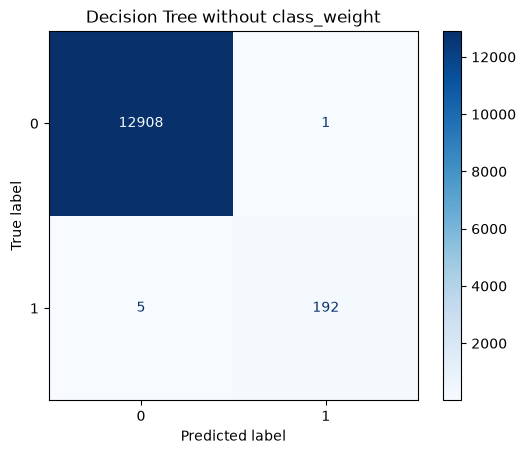

Model: Decision Tree with balanced class_weight
Accuracy: 0.9996947962765146
Precision: 0.9948717948717949
Recall: 0.9847715736040609
F-score: 0.9897959183673469


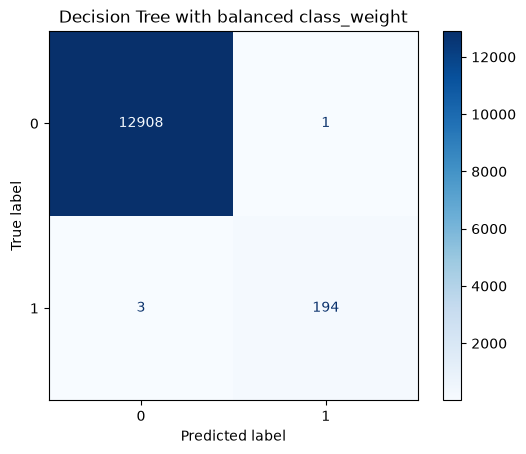

In [3]:
from sklearn.datasets import make_classification
from matplotlib import pyplot
from numpy import where
from collections import Counter
np.random.seed(1)

#without class-weight
clf1 = DecisionTreeClassifier(max_depth=5, random_state=1)
clf1 = clf1.fit(X_train, Y_train)
Y_predTest1 = clf1.predict(X_test)

#with class-weight
clf2 = DecisionTreeClassifier(max_depth=5, random_state=1, class_weight='balanced')
clf2 = clf2.fit(X_train, Y_train)
Y_predTest2 = clf2.predict(X_test)

def evaluate_model(clf, Y_pred, name):
    print('Model:', name)
    print('Accuracy:', accuracy_score(Y_test, Y_pred))
    print('Precision:', precision_score(Y_test, Y_pred, zero_division=0))
    print('Recall:', recall_score(Y_test, Y_pred, zero_division=0))
    print('F-score:', f1_score(Y_test, Y_pred, zero_division=0))
    ConfusionMatrixDisplay.from_estimator(clf, X_test, Y_test,display_labels=['0','1'],values_format = '.0f',cmap=plt.cm.Blues)
    plt.title(name)
    plt.show()

evaluate_model(clf1, Y_predTest1, 'Decision Tree without class_weight')
evaluate_model(clf2, Y_predTest2, 'Decision Tree with balanced class_weight')

Use the class-weight method from the tutorial for imbalanced classification on the creditcard-reduced.csv dataset to see whether class weights could improve the results.

At first, I set max_depth=2 for both models, but the results were exactly the same. I then increased the tree depth and ran the code again. This time, the results were different.

I first trained the model without class weights, which achieved an accuracy of 0.999542, precision of 0.994819, recall of 0.974619, and F-score of 0.984615. When I set class_weight='balanced', accuracy rose to 0.999695, precision reached 0.994872, recall improved to 0.984772, and the F-score went up to 0.989796.

The confusion matrices also show that the model without class weights correctly identified 192 fraudulent transactions and missed 5. With class weights, it correctly identified 194 fraudulent transactions and missed only 3. Both models incorrectly classified one normal transaction as fraudulent.

Overall, the model with class weights gave slightly better results.